In [2]:
import torch
import meta
import model

gpt2 = model.GPT2().to(meta.device)
gpt2.load_state_dict(torch.load("gpt2_qa.pt", map_location=meta.device, weights_only=True))
gpt2.eval()

/home/ozan/gpt2/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPT2(
  (embedding): Embedding(50257, 512)
  (positions): Embedding(256, 512)
  (dropout): Dropout(p=0.1, inplace=False)
  (layernormC): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
  (blocks): Sequential(
    (0): TransformerBlock(
      (layernormA): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
      (layernormB): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): MultiHeadAttention(
        (qkv_layer): Linear(in_features=512, out_features=1536, bias=False)
        (w0): Linear(in_features=512, out_features=512, bias=False)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (mlp): MLP(
        (mlp_expand): Linear(in_features=512, out_features=2048, bias=True)
        (mlp_contract): Linear(in_features=2048, out_features=512, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
    )
    (1): TransformerBlock(
      (layernormA): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=T

In [3]:
from torchinfo import summary

x = meta.tokenizer.encode(
  'This is a test. One that we have done countless times before.',
  return_tensors='pt'
  ).to(meta.device)

sumry = summary(gpt2, input_data=x, col_names=('input_size', 'output_size', 'num_params'))
print(x.shape)
print(sumry)

torch.Size([1, 14])
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
GPT2                                     [1, 14]                   [1, 14, 50257]            --
├─Embedding: 1-1                         [1, 14]                   [1, 14, 512]              25,731,584
├─Embedding: 1-2                         [14]                      [14, 512]                 131,072
├─Dropout: 1-3                           [1, 14, 512]              [1, 14, 512]              --
├─Sequential: 1-4                        [1, 14, 512]              [1, 14, 512]              --
│    └─TransformerBlock: 2-1             [1, 14, 512]              [1, 14, 512]              --
│    │    └─LayerNorm: 3-1               [1, 14, 512]              [1, 14, 512]              1,024
│    │    └─MultiHeadAttention: 3-2      [1, 14, 512]              [1, 14, 512]              1,048,576
│    │    └─LayerNorm: 3-3               [1, 14, 512]              [1, 14, 512]         

In [4]:
import torch.nn.functional as F

E = gpt2.embedding.weight.detach()   # [50257, 512], stop gradients
E_norm = F.normalize(E, dim=1)

In [5]:
words = [" one", " two", " three", "four", " red", " blue", " green", " cat", " dog", " bird", "apple", "company", "tree", "fruit"]
ids = [meta.tokenizer.encode(w)[0] for w in words]
sub = E_norm[ids]                       # [9, 512]
sim_matrix = sub @ sub.T                # [9, 9]

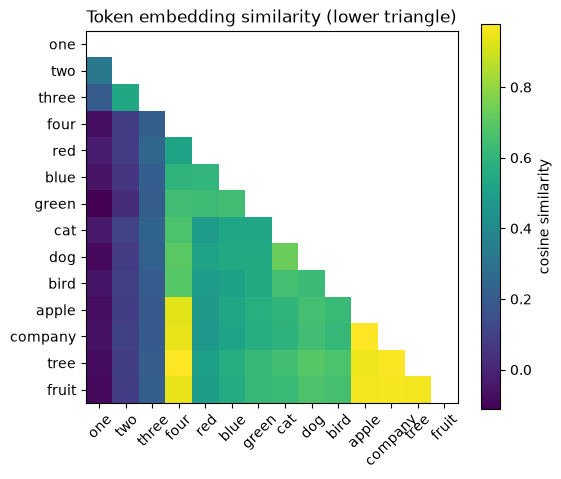

In [6]:
import matplotlib.pyplot as plt

m = sim_matrix.cpu().clone()
mask = torch.triu(torch.ones_like(m, dtype=torch.bool), diagonal=0)   # upper triangle + diagonal
m[mask] = float("nan")

plt.figure(figsize=(6, 5))
plt.imshow(m, cmap="viridis")
plt.colorbar(label="cosine similarity")
plt.xticks(range(len(words)), words, rotation=45)
plt.yticks(range(len(words)), words)
plt.title("Token embedding similarity (lower triangle)")
plt.show()

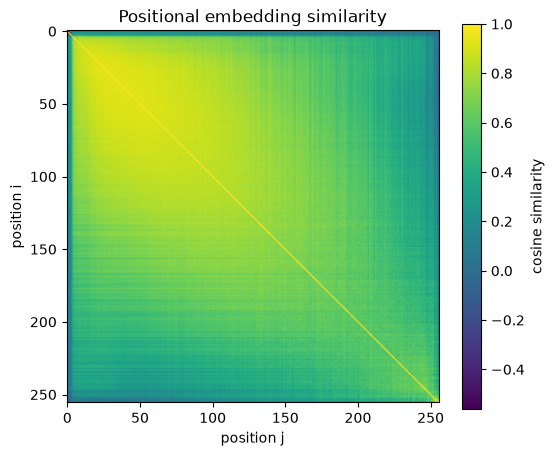

In [7]:
P = gpt2.positions.weight.detach().cpu()   # [256, 512], one row per position
P_norm = F.normalize(P, dim=1)
pos_sim = P_norm @ P_norm.T                 # [256, 256], position i vs position j

plt.figure(figsize=(6, 5))
plt.imshow(pos_sim, cmap="viridis")
plt.colorbar(label="cosine similarity")
plt.xlabel("position j")
plt.ylabel("position i")
plt.title("Positional embedding similarity")
plt.show()

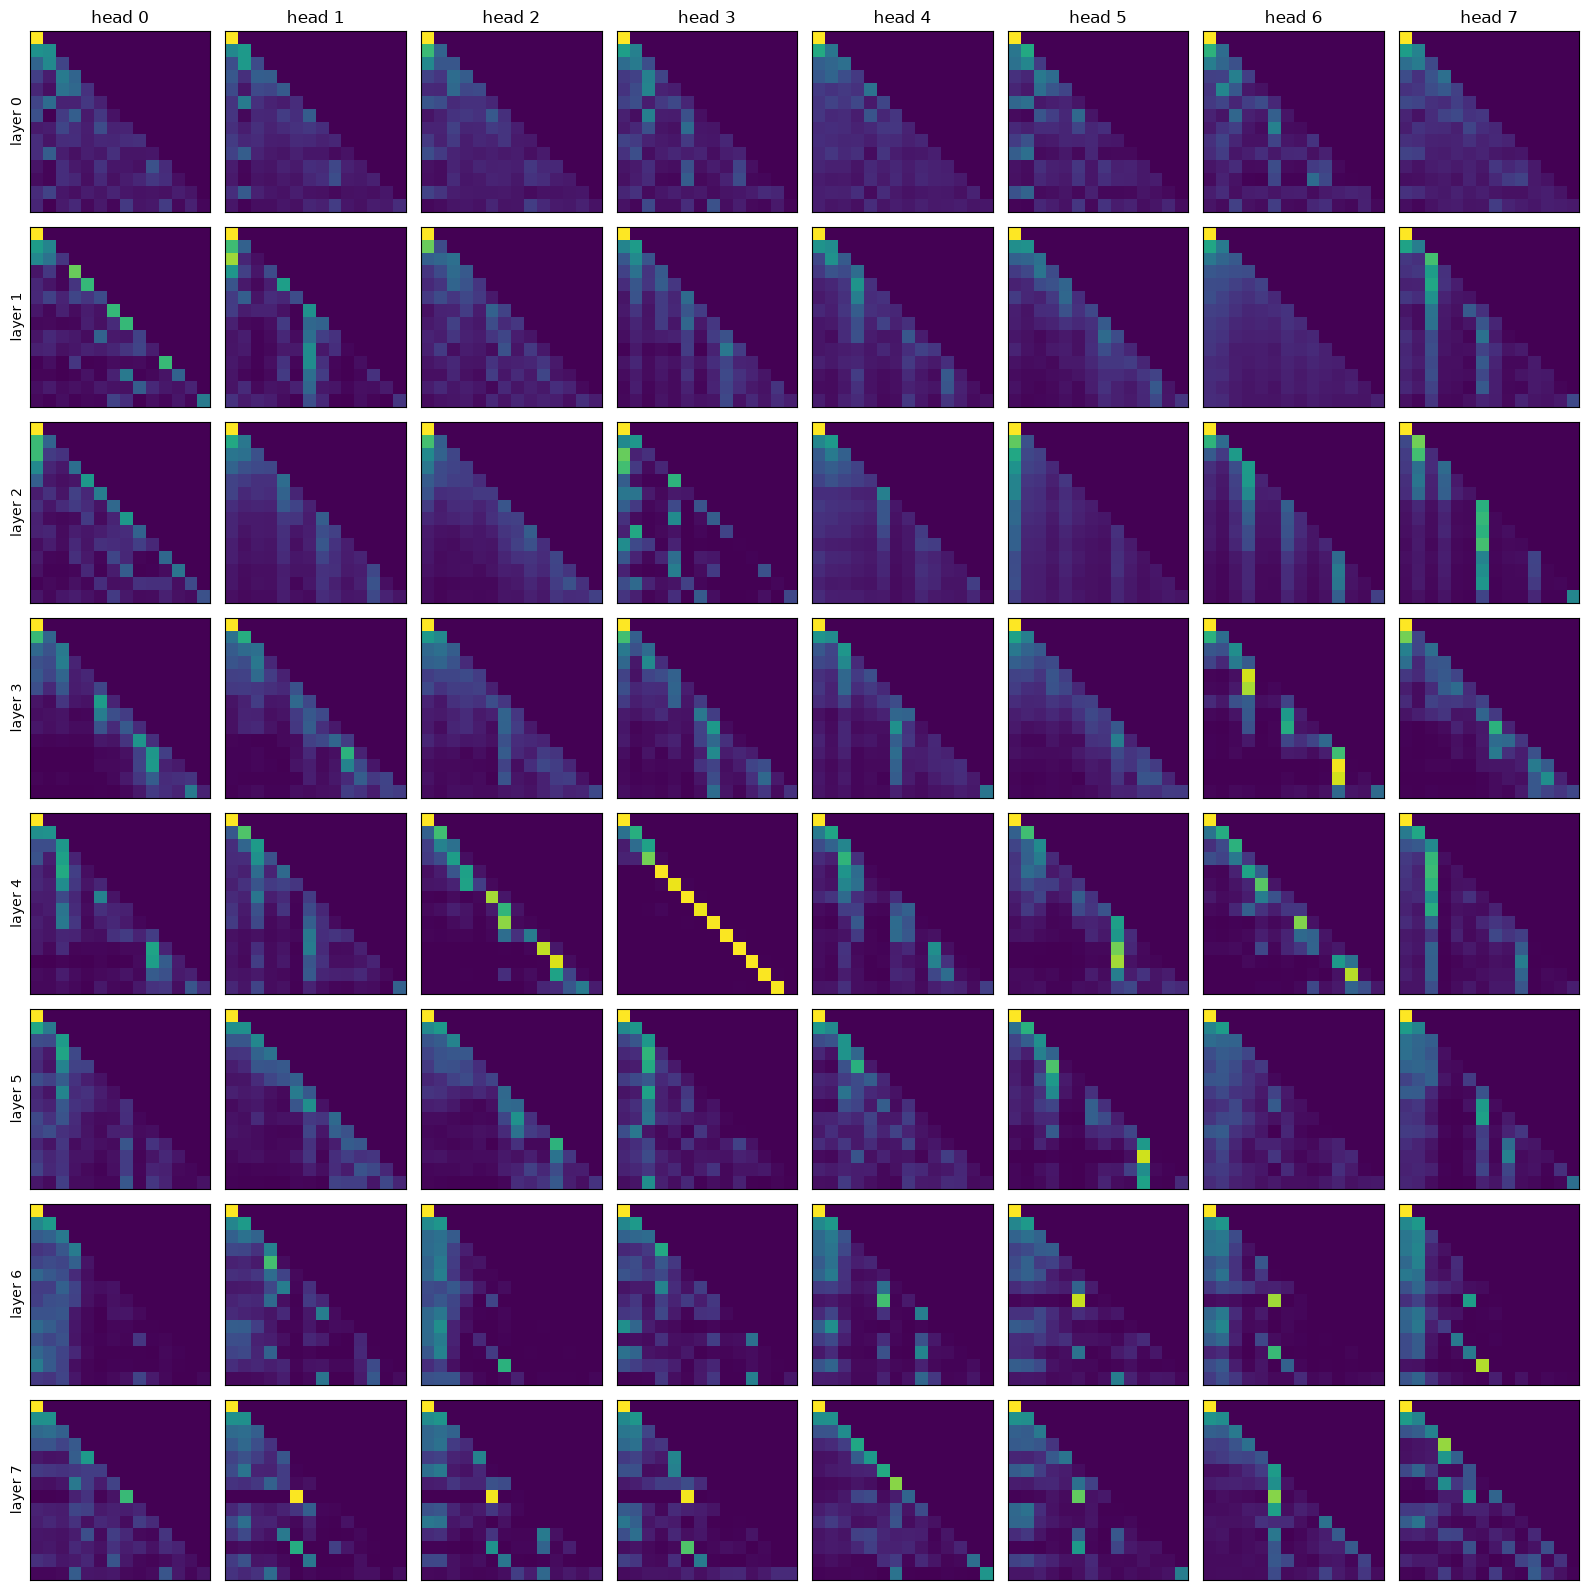

In [8]:
import math

attn_maps = []   # one (heads, T, T) tensor per layer

def save_attention(module, inputs, output):
  x = inputs[0]                                   # input to attention (after layernormA)
  B, T, C = x.shape
  head_dim = C // meta.n_heads
  q, k, _ = torch.chunk(module.qkv_layer(x), 3, dim=-1)
  q = q.view(B, T, meta.n_heads, head_dim).transpose(1, 2)
  k = k.view(B, T, meta.n_heads, head_dim).transpose(1, 2)
  scores = q @ k.transpose(-2, -1) / math.sqrt(head_dim)                     # (B, heads, T, T)
  mask = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), diagonal=1)
  scores = scores.masked_fill(mask, float("-inf"))                           # causal mask
  attn_maps.append(scores.softmax(dim=-1)[0].cpu())                          # drop batch dim

hooks = [block.attn.register_forward_hook(save_attention) for block in gpt2.blocks]

text = "The cat sat on the mat. The cat sat on the mat."
x = meta.tokenizer.encode(text, return_tensors="pt").to(meta.device)
with torch.no_grad():
  gpt2(x)

for h in hooks:
  h.remove()   # important: otherwise hooks keep firing on every future forward pass

tokens = [meta.tokenizer.decode(t) for t in x[0]]

# 8x8 grid: rows = layers, columns = heads
fig, axes = plt.subplots(meta.n_blocks, meta.n_heads, figsize=(16, 16))
for layer in range(meta.n_blocks):
  for head in range(meta.n_heads):
    ax = axes[layer, head]
    ax.imshow(attn_maps[layer][head], cmap="viridis")
    ax.set_xticks([]); ax.set_yticks([])
    if layer == 0:
      ax.set_title(f"head {head}")
    if head == 0:
      ax.set_ylabel(f"layer {layer}")
plt.tight_layout()
plt.show()

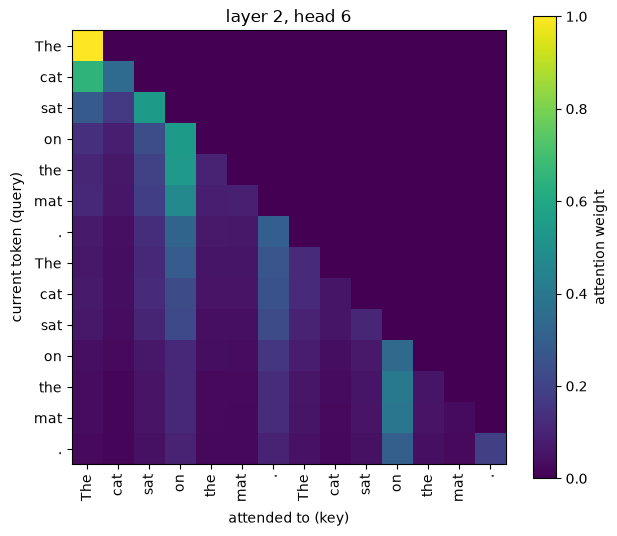

In [13]:
# zoom into one head with token labels; change these after spotting something in the grid
layer, head = 2,6

plt.figure(figsize=(7, 6))
plt.imshow(attn_maps[layer][head], cmap="viridis")
plt.colorbar(label="attention weight")
plt.xticks(range(len(tokens)), tokens, rotation=90)
plt.yticks(range(len(tokens)), tokens)
plt.xlabel("attended to (key)")
plt.ylabel("current token (query)")
plt.title(f"layer {layer}, head {head}")
plt.show()